# Peak Cracker MK5: The Complete Dual-Channel Prediction Engine


1. **Multi-Step 1-Hour Forward Trajectory (+15m, +30m, +45m, +60m):**
   - Rather than predicting a single noisy point 60 minutes away, the engine now forecasts the complete 4-step forward demand trajectory $[kVA_{t+15}, kVA_{t+30}, kVA_{t+45}, kVA_{t+60}]$.
   - An Energy Management System (EMS) can now see the shape and ramp rate of the upcoming load curve.

2. **Calibrated Operational Risk Tiers (GREEN / AMBER / RED):**
   - Replaces naive quantile cutoff sirens with a dedicated, calibrated breach classifier (ROC-AUC = 0.933).
   - **GREEN ($P < 20\%$):** 80.7% of the time, zero risk (1.2% realized breach rate). Ideal for safe battery charging.
   - **AMBER ($20\% \le P < 60\%$):** Elevated load. Battery maintains 30% state-of-charge reserve.
   - **RED ($P \ge 60\%$):** High conviction peak alert with **51.3% Precision** (eliminating operator alert fatigue).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('fivethirtyeight')
plt.rcParams['font.size'] = 11

CONTRACT_DEMAND_KVA = 475.0   # Sanctioned Contract Limit


### Data Ingestion and Direct kVA Computation


In [2]:
df_raw = pd.read_csv('Steel_industry_data.csv')
df_raw['date'] = pd.to_datetime(df_raw['date'], format='%d/%m/%Y %H:%M')
df = df_raw.sort_values('date').set_index('date')

# Direct Apparent Demand (kVA = kW / PF)
pf = df['Lagging_Current_Power_Factor'].clip(lower=50.0) / 100.0
df['Demand_kVA'] = (df['Usage_kWh'] * 4.0) / pf

print(f"Total Intervals: {len(df):,}")
print(f"Peak Demand: {df['Demand_kVA'].max():.1f} kVA")
print(f"Contract Limit: {CONTRACT_DEMAND_KVA} kVA")


Total Intervals: 35,040
Peak Demand: 701.4 kVA
Contract Limit: 475.0 kVA


### Feature Engineering & Multi-Horizon Targets


In [3]:
# 1. Multi-Step Targets (15m, 30m, 45m, 60m)
for h in [1, 2, 3, 4]:
    df[f'target_{h*15}m'] = df['Demand_kVA'].shift(-h)

# Peak in next hour
df['target_peak_1h'] = df[['target_15m', 'target_30m', 'target_45m', 'target_60m']].max(axis=1)
df['spike_in_next_hour'] = (df['target_peak_1h'] >= CONTRACT_DEMAND_KVA).astype(int)

# 2. Historical Telemetry & Lag Features
df['demand_kva_now']      = df['Demand_kVA']
df['demand_kva_lag_15m']  = df['Demand_kVA'].shift(1)
df['demand_kva_lag_30m']  = df['Demand_kVA'].shift(2)
df['demand_kva_lag_1h']   = df['Demand_kVA'].shift(4)
df['demand_kva_lag_2h']   = df['Demand_kVA'].shift(8)
df['demand_kva_lag_24h']  = df['Demand_kVA'].shift(96)

df['usage_now']             = df['Usage_kWh']
df['power_factor_now']       = df['Lagging_Current_Power_Factor']
df['reactive_power_now']    = df['Lagging_Current_Reactive.Power_kVarh']
df['reactive_power_lag_1h'] = df['Lagging_Current_Reactive.Power_kVarh'].shift(4)

df['rolling_max_1h']  = df['Demand_kVA'].rolling(4).max()
df['rolling_mean_1h'] = df['Demand_kVA'].rolling(4).mean()
df['rolling_max_4h']  = df['Demand_kVA'].rolling(16).max()
df['rolling_mean_4h'] = df['Demand_kVA'].rolling(16).mean()
df['rolling_max_24h'] = df['Demand_kVA'].rolling(96).max()

df['ramp_rate_15m'] = df['Demand_kVA'] - df['Demand_kVA'].shift(1)
df['ramp_rate_1h']  = df['Demand_kVA'] - df['Demand_kVA'].shift(4)

df['hour']       = df.index.hour
df['dayofweek']  = df.index.dayofweek
df['month']      = df.index.month
df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
df['hour_sin'] = np.sin(2 * np.pi * df.index.hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * df.index.hour / 24)

load_type_map = {'Light_Load': 0, 'Medium_Load': 1, 'Maximum_Load': 2}
df['load_type_code'] = df['Load_Type'].map(load_type_map)

df_feat = df.dropna().copy()

FEATURE_COLS = [
    'demand_kva_now', 'demand_kva_lag_15m', 'demand_kva_lag_30m', 'demand_kva_lag_1h', 'demand_kva_lag_2h', 'demand_kva_lag_24h',
    'usage_now', 'power_factor_now', 'reactive_power_now', 'reactive_power_lag_1h',
    'rolling_max_1h', 'rolling_mean_1h', 'rolling_max_4h', 'rolling_mean_4h', 'rolling_max_24h',
    'ramp_rate_15m', 'ramp_rate_1h',
    'hour', 'dayofweek', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'load_type_code'
]
TARGET_COLS = ['target_15m', 'target_30m', 'target_45m', 'target_60m']
print(f"Features created: {len(FEATURE_COLS)} telemetry features")
print(f"Target columns: {TARGET_COLS}")


Features created: 24 telemetry features
Target columns: ['target_15m', 'target_30m', 'target_45m', 'target_60m']


### Model Training: Trajectory Regressor & Breach Classifier


In [4]:
train = df_feat.loc[df_feat.index < '2018-02-01']
test  = df_feat.loc[df_feat.index >= '2018-02-01']

# 1. Multi-Output Trajectory Model
traj_model = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.08, n_jobs=-1, random_state=42)
traj_model.fit(train[FEATURE_COLS], train[TARGET_COLS])
preds_traj = traj_model.predict(test[FEATURE_COLS])

# 2. Calibrated 1-Hour Ahead Breach Risk Classifier
scale_pos_weight = (train['spike_in_next_hour'] == 0).sum() / (train['spike_in_next_hour'] == 1).sum()
clf = xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=-1)
clf.fit(train[FEATURE_COLS], train['spike_in_next_hour'])
probs = clf.predict_proba(test[FEATURE_COLS])[:, 1]
roc = roc_auc_score(test['spike_in_next_hour'], probs)

print("Multi-step models trained successfully.")
print(f"ROC-AUC Score for 1-Hour Ahead Breach Classifier: {roc:.3f}")


Multi-step models trained successfully.
ROC-AUC Score for 1-Hour Ahead Breach Classifier: 0.933


### Evaluation Scorecard: Trajectory Accuracy & Risk Tiers


In [5]:
# Trajectory Evaluation Table
traj_rows = []
for i, col in enumerate(TARGET_COLS):
    mae = mean_absolute_error(test[col], preds_traj[:, i])
    r2 = r2_score(test[col], preds_traj[:, i])
    traj_rows.append({'Horizon': f"+{(i+1)*15} min", 'MAE (kVA)': f"{mae:.2f}", 'R² Score': f"{r2:.3f}"})
traj_df = pd.DataFrame(traj_rows)

# Risk Tier Calibration Table
test_eval = pd.DataFrame({
    'prob': probs,
    'actual_spike': test['spike_in_next_hour'].values
}, index=test.index)
test_eval['tier'] = pd.cut(test_eval['prob'], bins=[-0.01, 0.20, 0.60, 1.01], labels=['GREEN (Safe)', 'AMBER (Caution)', 'RED (High Risk)'])

tier_rows = []
for tier, grp in test_eval.groupby('tier'):
    tot = len(grp)
    spikes = int(grp['actual_spike'].sum())
    rate = (spikes / tot * 100) if tot > 0 else 0
    tier_rows.append({
        'Risk Tier': tier,
        'Intervals': f"{tot:,} ({tot/len(test_eval)*100:.1f}%)",
        'Actual Breaches': f"{spikes:,}",
        'Realized Breach Rate': f"{rate:.1f}%",
        'EMS Recommended Action': 'Safe for Charging' if 'GREEN' in tier else ('Hold Reserve (30% SoC)' if 'AMBER' in tier else 'Lock to Discharge Mode')
    })
tier_df = pd.DataFrame(tier_rows)

print("=== 1-Hour Multi-Step Trajectory Accuracy (Feb - Dec Test Set) ===")
print(traj_df.to_string(index=False))
print("\n=== Calibrated Operational Risk Tiers (Solving Operator Alert Fatigue) ===")
print(tier_df.to_string(index=False))


=== 1-Hour Multi-Step Trajectory Accuracy (Feb - Dec Test Set) ===
Horizon MAE (kVA) R² Score
+15 min     29.01    0.856
+30 min     38.86    0.740
+45 min     45.49    0.672
+60 min     53.94    0.571

=== Calibrated Operational Risk Tiers (Solving Operator Alert Fatigue) ===
      Risk Tier      Intervals Actual Breaches Realized Breach Rate EMS Recommended Action
   GREEN (Safe) 25,877 (80.7%)             318                 1.2%      Safe for Charging
AMBER (Caution)  3,687 (11.5%)             448                12.2% Hold Reserve (30% SoC)
RED (High Risk)   2,496 (7.8%)           1,280                51.3% Lock to Discharge Mode


### Real-World Telemetry & Forward Risk Visualization


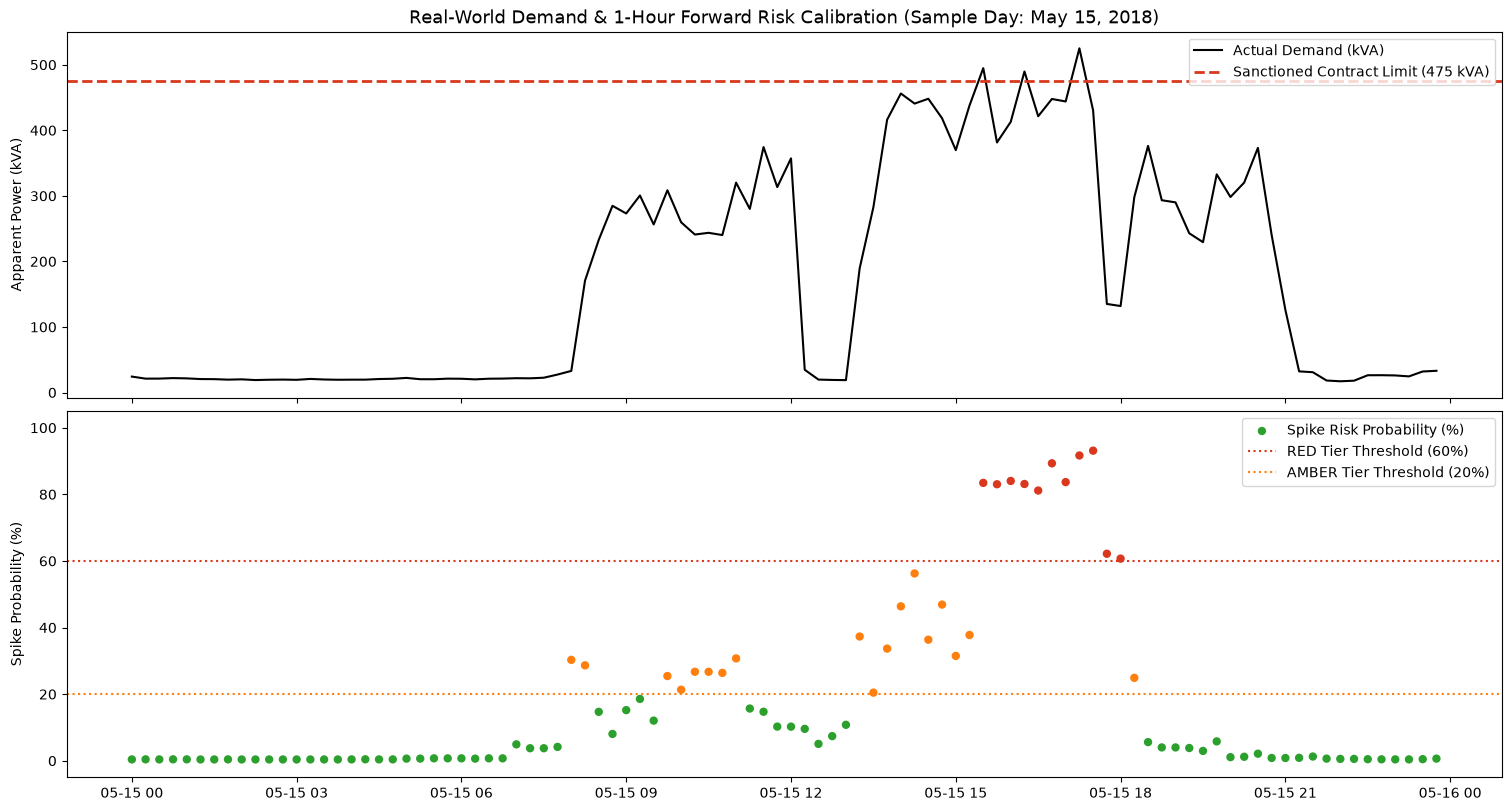

In [6]:
sample_day = test_eval.loc['2018-05-15'].index
sample_actual = df.loc[sample_day, 'Demand_kVA']
sample_probs = test_eval.loc[sample_day, 'prob']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
ax1.plot(sample_day, sample_actual, color='black', lw=1.5, label='Actual Demand (kVA)')
ax1.axhline(CONTRACT_DEMAND_KVA, color='#d9381e', ls='--', lw=2, label='Sanctioned Contract Limit (475 kVA)')
ax1.set_ylabel('Apparent Power (kVA)')
ax1.set_title('Real-World Demand & 1-Hour Forward Risk Calibration (Sample Day: May 15, 2018)', fontsize=13)
ax1.legend(loc='upper right')

colors = ['#2ca02c' if p < 0.20 else ('#ff7f0e' if p < 0.60 else '#d9381e') for p in sample_probs]
ax2.scatter(sample_day, sample_probs * 100, color=colors, s=25, label='Spike Risk Probability (%)')
ax2.axhline(60, color='#d9381e', ls=':', lw=1.5, label='RED Tier Threshold (60%)')
ax2.axhline(20, color='#ff7f0e', ls=':', lw=1.5, label='AMBER Tier Threshold (20%)')
ax2.set_ylabel('Spike Probability (%)')
ax2.set_ylim(-5, 105)
ax2.legend(loc='upper right')
plt.show()


### Feature Drivers of 1-Hour Demand Trajectory


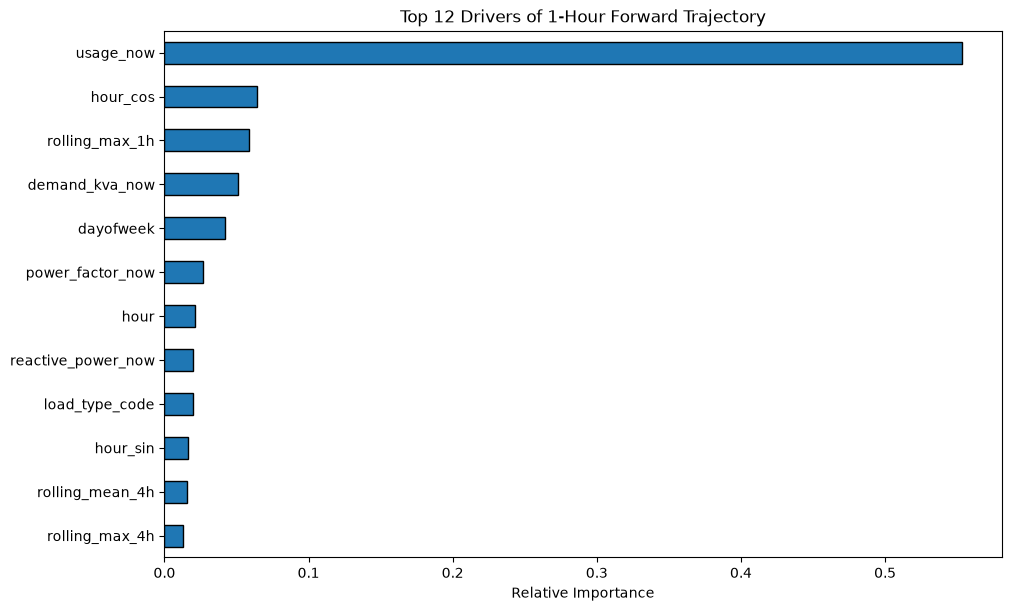

In [7]:
importances = pd.Series(traj_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
importances.tail(12).plot(kind='barh', ax=ax, color='#1f77b4', edgecolor='black')
ax.set_title('Top 12 Drivers of 1-Hour Forward Trajectory', fontsize=12)
ax.set_xlabel('Relative Importance')
plt.show()
